In [1]:
%pip install geopandas -q


StatementMeta(, b7001278-b678-43c2-a77c-c3d67564085a, 7, Finished, Available, Finished, True)


Note: you may need to restart the kernel to use updated packages.



In [5]:
import geopandas as gpd, pandas as pd, numpy as np, os
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.inspection import permutation_importance
import mlflow; mlflow.autolog(disable=True)

# ---------- Paramètres ----------
notebookutils.fs.mount("abfss://citiz_hackathon@onelake.dfs.fabric.microsoft.com/lakehouse_silver.Lakehouse", "/silver")
notebookutils.fs.mount("abfss://citiz_hackathon@onelake.dfs.fabric.microsoft.com/lakehouse_gold.Lakehouse", "/gold")
S = notebookutils.fs.getMountPath("/silver") + "/Files"
G = notebookutils.fs.getMountPath("/gold") + "/Files/objectif_3"
os.makedirs(G, exist_ok=True)

f = gpd.read_parquet(f"{S}/features/features_carreaux.parquet").to_crs(2154).reset_index(drop=True)
X_COLS = ["densite_hab_km2", "part_sans_voiture", "revenu_moyen", "part_logements_collectifs", "part_65_plus",
          "nb_options_tc_5min", "departs_pointe_5min", "nb_activites_400m", "nb_parkings_400m", "dist_gare_m"]
f[X_COLS] = f[X_COLS].astype(float).fillna(f[X_COLS].astype(float).median())

mrs = f[f.ville == "marseille"].reset_index(drop=True)
tln = f[f.ville == "toulon"].reset_index(drop=True)
y = (mrs.citiz_stations_5min > 0).astype(int).values
groupes = (mrs.centroid.x // 1000).astype(int).astype(str) + "_" + (mrs.centroid.y // 1000).astype(int).astype(str)

def top10(y, s):
    k = int(len(s) * 0.10)
    return y[np.argsort(-s)[:k]].sum() / y.sum()

modeles = {
    "base_densite_seule": (["densite_hab_km2"], make_pipeline(StandardScaler(), LogisticRegression())),
    "regression_logistique": (X_COLS, make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))),
    "gradient_boosting": (X_COLS, HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=0)),
}

# ---------- 1. Validation spatiale : blocs de 1 km, 5 plis ----------
res = []
for nom, (cols, mod) in modeles.items():
    Xm, s = mrs[cols].values, np.zeros(len(y))
    for tr, te in GroupKFold(n_splits=5).split(Xm, y, groupes):
        mod.fit(Xm[tr], y[tr])
        s[te] = mod.predict_proba(Xm[te])[:, 1]
    res.append({"modele": nom, "AUC": roc_auc_score(y, s), "precision_moyenne": average_precision_score(y, s),
                "part_citiz_dans_top10pct": top10(y, s)})
metriques = pd.DataFrame(res).round(3)
print(metriques.to_string(index=False))

# ---------- 2. Meilleur modèle → entraîné sur tout Marseille ----------
meilleur = metriques[metriques.modele != "base_densite_seule"].sort_values("AUC").modele.iloc[-1]
cols, mod = modeles[meilleur]
mod.fit(mrs[cols].values, y)
imp = permutation_importance(mod, mrs[cols].values, y, scoring="roc_auc", n_repeats=5, random_state=0)
importance = pd.Series(imp.importances_mean, index=cols).sort_values(ascending=False).round(3)
print("\nMeilleur modèle :", meilleur)
print("\nCe qui compte le plus (importance) :\n", importance.to_string())

# ---------- 3. Score Citiz pour chaque carreau de Toulon ----------
tln["score_citiz"] = mod.predict_proba(tln[cols].values)[:, 1]
tln["rang_score"] = tln.score_citiz.rank(ascending=False).astype(int)

# ---------- 4. Suivi MLflow (intégré à Fabric) ----------
try:
    import mlflow
    mlflow.set_experiment("citiz_toulon_objectif_3")
    with mlflow.start_run(run_name=meilleur):
        mlflow.log_param("variables", ", ".join(X_COLS))
        mlflow.log_param("validation", "GroupKFold 5 plis, blocs de 1 km")
        for _, r in metriques.iterrows():
            mlflow.log_metrics({f"{r.modele}_AUC": r.AUC, f"{r.modele}_AP": r.precision_moyenne,
                                f"{r.modele}_top10": r.part_citiz_dans_top10pct})
    print("\nRésultats enregistrés dans l'expérience MLflow 'citiz_toulon_objectif_3'")
except Exception as e:
    print("MLflow non disponible :", e)

metriques.to_csv(f"{G}/metriques_modele.csv", index=False)
importance.to_csv(f"{G}/importance_variables.csv")

StatementMeta(, b7001278-b678-43c2-a77c-c3d67564085a, 12, Finished, Available, Finished, False)

/home/trusted-service-user/cluster-env/trident_env/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/trusted-service-user/cluster-env/trident_env/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/trusted-service-user/cluster-env/trident_env/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/trusted-service-user/cluster-env/trident_env/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/trusted-service-user/cluster-env/trident_env/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/trus

               modele   AUC  precision_moyenne  part_citiz_dans_top10pct
   base_densite_seule 0.872              0.323                     0.512
regression_logistique 0.949              0.672                     0.746
    gradient_boosting 0.965              0.785                     0.798

Meilleur modèle : gradient_boosting

Ce qui compte le plus (importance) :
 nb_activites_400m            0.060
revenu_moyen                 0.023
part_sans_voiture            0.007
part_logements_collectifs    0.006
dist_gare_m                  0.005
departs_pointe_5min          0.005
part_65_plus                 0.003
densite_hab_km2              0.002
nb_options_tc_5min           0.001
nb_parkings_400m             0.001



Résultats enregistrés dans l'expérience MLflow 'citiz_toulon_objectif_3'


StatementMeta(, b7001278-b678-43c2-a77c-c3d67564085a, 13, Finished, Available, Finished, False)

Couverture à 5 min calculée pour 4603 carreaux
Sauvegardé : tables 'scores_toulon' et 'sites_recommandes' dans lakehouse_gold


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

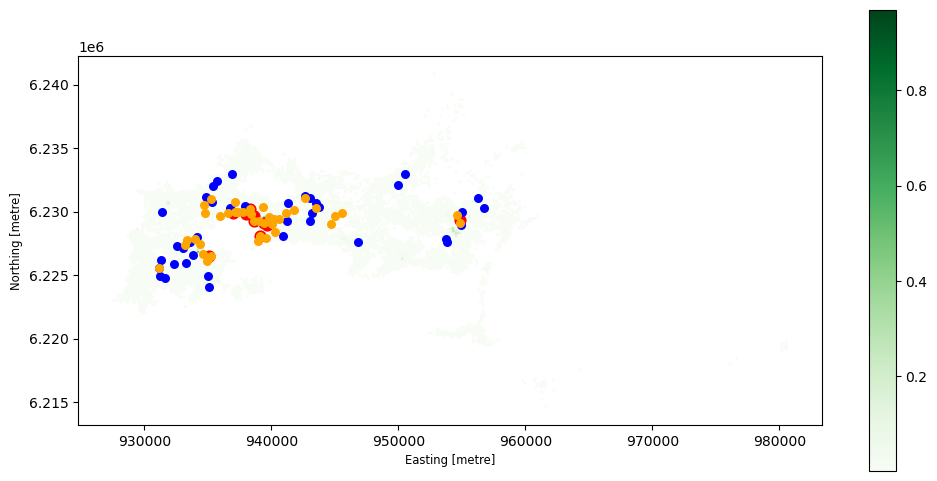

In [6]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
from scipy.spatial import cKDTree
from pyproj import Transformer

BRONZE = "/lakehouse/default/Files"
MARCHE = 400

# ---------- HYPOTHÈSES DE COÛT (€, installation + 1re année) — À REMPLACER PAR LES CHIFFRES CITIZ / AOM ----------
COUT = {"citiz": 25000, "arret_bus": 15000, "station_velo": 40000}
VOITURES_PAR_STATION = 2
KM_EVITES_PAR_VOITURE = (10000, 19000)   # ADEME, enquête autopartage 2022
KG_CO2_PAR_KM = 0.2                      # ordre de grandeur voiture particulière (à vérifier, Base Empreinte ADEME)

# ---------- 1. Réseau piéton Toulon → quels carreaux un site couvre à 5 min ----------
noeuds = pd.read_parquet(f"{BRONZE}/osm/toulon/pieton_noeuds.parquet", columns=["id", "lon", "lat"]).drop_duplicates("id").reset_index(drop=True)
tr = gpd.read_parquet(f"{BRONZE}/osm/toulon/pieton_troncons.parquet")
if "length" not in tr.columns: tr["length"] = tr.to_crs(2154).length
pos = pd.Series(np.arange(len(noeuds)), index=noeuds["id"].astype("int64"))
u = tr["u"].astype("int64").map(pos); v = tr["v"].astype("int64").map(pos); w = pd.to_numeric(tr["length"], errors="coerce")
ok = u.notna() & v.notna() & w.notna()
e = pd.DataFrame({"a": np.r_[u[ok], v[ok]].astype(int), "b": np.r_[v[ok], u[ok]].astype(int), "w": np.r_[w[ok], w[ok]]}).groupby(["a", "b"], as_index=False)["w"].min()
Gr = csr_matrix((e.w.values, (e.a.values, e.b.values)), shape=(len(noeuds), len(noeuds)))
x_, y_ = Transformer.from_crs(4326, 2154, always_xy=True).transform(noeuds.lon.astype(float).values, noeuds.lat.astype(float).values)
arbre = cKDTree(np.c_[x_, y_])

c = tln
d_c, n_c = arbre.query(np.c_[c.centroid.x, c.centroid.y])
paires, sources = [], np.unique(n_c)
for i in range(0, len(sources), 150):
    src = sources[i:i + 150]
    D = dijkstra(Gr, indices=src, limit=MARCHE)[:, n_c]
    r, k = np.nonzero(np.isfinite(D))
    paires.append(pd.DataFrame({"noeud": src[r], "j": k, "d": D[r, k]}))
P = pd.concat(paires).merge(pd.DataFrame({"noeud": n_c, "i": np.arange(len(c))}), on="noeud")
P = P[P.d + d_c[P.i.values] + d_c[P.j.values] <= MARCHE]
couvre = {i: g.j.values for i, g in P.groupby("i")}
print("Couverture à 5 min calculée pour", len(couvre), "carreaux")

# ---------- 2. Candidats et valeur de chaque carreau ----------
ind = c["ind"].values.astype(float)
sans_voit = c["menages_sans_voiture_est"].values.astype(float)
deja_tc = (c["nb_options_tc_5min"] > 0).values
opt = gpd.read_parquet(f"{S}/acces_5min/options.parquet")
bus = opt[(opt["ville"] == "toulon") & (opt["type"] == "bus")]
dist_bus, _ = cKDTree(bus[["x", "y"]].values).query(np.c_[c.centroid.x, c.centroid.y])

types = {
    # Citiz : on maximise les habitants « qui ressemblent à des clients Citiz » (score × habitants)
    "citiz":        dict(candidats=np.where((c.nb_parkings_400m > 0) & (c.ind > 0))[0], valeur=c.score_citiz.values * ind, deja=np.zeros(len(c), bool)),
    # Arrêt de bus : seulement là où il n'y a aucune option aujourd'hui, mais une ligne à moins de 800 m
    "arret_bus":    dict(candidats=np.where(~deja_tc & (dist_bus <= 800) & (c.ind > 0))[0], valeur=ind, deja=deja_tc.copy()),
    # Station vélo : Toulon n'en a aucune
    "station_velo": dict(candidats=np.where(c.ind > 0)[0], valeur=ind, deja=np.zeros(len(c), bool)),
}

# ---------- 3. Choix glouton : à chaque tour, le site qui ajoute le plus ; arrêt quand ça ne vaut plus le coup ----------
def glouton(type_, candidats, valeur, deja, n_max=40, seuil=0.10):
    couvert, choix, premier = deja.copy(), [], None
    for rang in range(1, n_max + 1):
        meilleur_i, meilleur_v = None, 0
        for i in candidats:
            js = couvre.get(i, np.array([i]))
            vv = valeur[js][~couvert[js]].sum()
            if vv > meilleur_v: meilleur_i, meilleur_v = i, vv
        if meilleur_i is None: break
        if premier is None: premier = meilleur_v
        if meilleur_v < seuil * premier: break                     # apporte moins de 10 % du premier site → on s'arrête
        js = couvre.get(meilleur_i, np.array([meilleur_i]))
        nouveaux = js[~couvert[js]]
        couvert[nouveaux] = True
        choix.append({"type": type_, "rang_dans_type": rang, "idcar_200m": c.idcar_200m.iloc[meilleur_i],
                      "score_citiz": round(float(c.score_citiz.iloc[meilleur_i]), 3) if type_ == "citiz" else np.nan,
                      "habitants_nouveaux": round(ind[nouveaux].sum()),
                      "menages_sans_voiture_nouveaux": round(sans_voit[nouveaux].sum()),
                      "cout_eur": COUT[type_], "geometry": c.centroid.iloc[meilleur_i]})
    return pd.DataFrame(choix)

sites = gpd.GeoDataFrame(pd.concat([glouton(t, **p) for t, p in types.items()], ignore_index=True), crs=2154)
sites["habitants_par_1000_eur"] = (sites.habitants_nouveaux / (sites.cout_eur / 1000)).round(1)

# ---------- 4. Classement global sous budget (on garde l'ordre de chaque type) + CO2 ----------
sites = sites.sort_values(["type", "rang_dans_type"])
sites["priorite"] = sites.groupby("type")["habitants_par_1000_eur"].cummin()
sites = sites.sort_values(["priorite", "rang_dans_type"], ascending=[False, True]).reset_index(drop=True)
sites["rang_global"] = np.arange(1, len(sites) + 1)
sites["cout_cumule_eur"] = sites.cout_eur.cumsum()
est_citiz = sites["type"] == "citiz"
sites["co2_evite_t_an_bas"]  = np.where(est_citiz, VOITURES_PAR_STATION * KM_EVITES_PAR_VOITURE[0] * KG_CO2_PAR_KM / 1000, 0)
sites["co2_evite_t_an_haut"] = np.where(est_citiz, VOITURES_PAR_STATION * KM_EVITES_PAR_VOITURE[1] * KG_CO2_PAR_KM / 1000, 0)

# ---------- 5. Sauvegarder dans lakehouse_gold ----------
tln.to_parquet(f"{G}/scores_toulon.parquet")
sites.to_parquet(f"{G}/sites_recommandes.parquet")

def vers_table(gdf, nom):
    t = pd.DataFrame(gdf.drop(columns="geometry"))
    p = gdf.centroid.to_crs(4326)
    t["lon"], t["lat"] = p.x, p.y
    if nom == "scores_toulon": t["wkt"] = gdf.to_crs(4326).geometry.to_wkt()
    for col in t.columns:
        if t[col].dtype == object: t[col] = t[col].astype(str)
    sdf = spark.createDataFrame(t)
    try:    sdf.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"lakehouse_gold.dbo.{nom}")
    except Exception: sdf.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"lakehouse_gold.{nom}")
vers_table(tln[["idcar_200m", "ind", "score_citiz", "rang_score", "geometry"]], "scores_toulon")
vers_table(sites, "sites_recommandes")
print("Sauvegardé : tables 'scores_toulon' et 'sites_recommandes' dans lakehouse_gold")

ax = tln.plot(column="score_citiz", cmap="Greens", figsize=(12, 7), legend=True)
sites[est_citiz].sort_values("rang_dans_type").head(10).plot(ax=ax, color="red", markersize=60)
sites[sites["type"] == "arret_bus"].plot(ax=ax, color="blue", markersize=30)
sites[sites["type"] == "station_velo"].plot(ax=ax, color="orange", markersize=30)

In [8]:
print("=== Validation du modèle (Marseille, blocs de 1 km) ===")
print(metriques.to_string(index=False))
print("\n=== Ce qui compte le plus ===\n", importance.to_string())

cols = ["rang_dans_type", "idcar_200m", "score_citiz", "habitants_nouveaux", "menages_sans_voiture_nouveaux", "cout_eur"]
print("\n=== Stations Citiz recommandées à Toulon (dans l'ordre de choix) ===")
print(sites[sites["type"] == "citiz"].sort_values("rang_dans_type").head(10)[cols].to_string(index=False))
for t in ["arret_bus", "station_velo"]:
    print(f"\n=== {t} : 5 premiers ===")
    print(sites[sites["type"] == t].sort_values("rang_dans_type").head(5)[cols[:2] + cols[3:]].to_string(index=False))

print("\nNombre de sites retenus par type :", sites["type"].value_counts().to_dict())
print("\n=== Ce que donne chaque budget (tous types, par ordre de priorité) ===")
for b in [100_000, 250_000, 500_000]:
    s = sites[sites.cout_cumule_eur <= b]
    print(f"{b:>9,} € → {len(s):2d} sites {s['type'].value_counts().to_dict()} | "
          f"{s.habitants_nouveaux.sum():>7,.0f} habitants | {s.menages_sans_voiture_nouveaux.sum():>6,.0f} ménages sans voiture | "
          f"CO₂ évité {s.co2_evite_t_an_bas.sum():.0f}–{s.co2_evite_t_an_haut.sum():.0f} t/an")

StatementMeta(, b7001278-b678-43c2-a77c-c3d67564085a, 15, Finished, Available, Finished, False)

=== Validation du modèle (Marseille, blocs de 1 km) ===
               modele   AUC  precision_moyenne  part_citiz_dans_top10pct
   base_densite_seule 0.872              0.323                     0.512
regression_logistique 0.949              0.672                     0.746
    gradient_boosting 0.965              0.785                     0.798

=== Ce qui compte le plus ===
 nb_activites_400m            0.060
revenu_moyen                 0.023
part_sans_voiture            0.007
part_logements_collectifs    0.006
dist_gare_m                  0.005
departs_pointe_5min          0.005
part_65_plus                 0.003
densite_hab_km2              0.002
nb_options_tc_5min           0.001
nb_parkings_400m             0.001

=== Stations Citiz recommandées à Toulon (dans l'ordre de choix) ===
 rang_dans_type                     idcar_200m  score_citiz  habitants_nouveaux  menages_sans_voiture_nouveaux  cout_eur
              1 CRS3035RES200mN2232600E3989800        0.603                3967

In [9]:
iris = gpd.read_parquet("/lakehouse/default/Files/cartes/iris_toulon_marseille.parquet").to_crs(2154)
noms = gpd.sjoin(sites[["rang_global", "geometry"]], iris[["NOM_COM", "NOM_IRIS", "geometry"]], how="left", predicate="within")
noms = noms[~noms.index.duplicated()]
sites["commune"], sites["quartier"] = noms["NOM_COM"].values, noms["NOM_IRIS"].values
sites.to_parquet(f"{G}/sites_recommandes.parquet")
vers_table(sites, "sites_recommandes")
print(sites.sort_values("rang_global").head(15)[["rang_global", "type", "commune", "quartier", "habitants_nouveaux", "cout_cumule_eur"]].to_string(index=False))

StatementMeta(, b7001278-b678-43c2-a77c-c3d67564085a, 16, Finished, Available, Finished, False)

 rang_global         type              commune                       quartier  habitants_nouveaux  cout_cumule_eur
           1        citiz               Toulon                  Dutasta-Mayol                3967            25000
           2 station_velo               Toulon                    Saint-Louis                5740            65000
           3 station_velo               Toulon                   Saint-Roch I                4975           105000
           4        citiz               Toulon            Haute Ville-La Gare                3087           130000
           5        citiz               Toulon Port Marchand-Port de Commerce                4460           155000
           6        citiz               Toulon                    Saint-Louis                5120           180000
           7 station_velo               Toulon                       Aguillon                4582           220000
           8 station_velo               Toulon Port Marchand-Port de Commerce   